In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
full_df = pd.read_csv("SAML-D.csv")

In [3]:
full_df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [4]:
df_fraud = full_df[full_df['Is_laundering'] == 1]
df_fraud.shape

(9873, 12)

In [5]:
df_n_fraud =  full_df[full_df['Is_laundering'] == 0]
df_n_fraud.shape

(9494979, 12)

In [6]:
df_n_fraud_sample = df_n_fraud.sample(n=df_fraud.shape[0], random_state=42)

In [7]:
df_combined = pd.concat([df_fraud, df_n_fraud_sample], axis=0)

In [8]:
df_combined.shape

(19746, 12)

In [9]:
df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

### Splitting into X and y

In [10]:
df_combined.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,07:40:08,2023-07-14,3187084517,8846937355,3788.78,UK pounds,UK pounds,UK,UK,Cash Deposit,1,Smurfing
1,22:04:14,2022-10-29,4851027632,9832274459,7377.62,UK pounds,Euro,UK,France,Cross-border,0,Normal_Fan_Out
2,16:56:30,2023-02-06,5811105590,6929936460,7435.30,UK pounds,Moroccan dirham,UK,Italy,Cross-border,0,Normal_Fan_Out
3,22:40:35,2023-01-09,4349340373,386440627,7057.37,UK pounds,Euro,UK,Germany,Cross-border,1,Structuring
4,19:53:44,2023-01-13,5386067899,8286125964,7443.71,UK pounds,UK pounds,UK,UK,Credit card,0,Normal_Fan_Out


In [11]:
df_combined.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='str')

In [12]:
X = df_combined.drop(columns=['Time', 'Date', 'Sender_account', 'Receiver_account', 'Is_laundering', 'Laundering_type'])
y = df_combined['Is_laundering']

### Get the train test split

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
print(len(X_train))
print(len(y_train))
print(len(X_test))
print(len(y_test))

15796
15796
3950
3950


In [16]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 15796 entries, 14731 to 15795
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Amount                  15796 non-null  float64
 1   Payment_currency        15796 non-null  str    
 2   Received_currency       15796 non-null  str    
 3   Sender_bank_location    15796 non-null  str    
 4   Receiver_bank_location  15796 non-null  str    
 5   Payment_type            15796 non-null  str    
dtypes: float64(1), str(5)
memory usage: 1.3 MB


In [17]:
cat_cols = ['Payment_currency', 'Received_currency', 'Sender_bank_location','Receiver_bank_location', 'Payment_type']

### Importing Encoders and ColumnTransfomer

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat_cols', 
        OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), 
        cat_cols)],
        remainder='passthrough'
)

### Importing Decision Tree Classifier

In [20]:
from sklearn.tree import DecisionTreeClassifier

In [21]:
from sklearn.pipeline import Pipeline 

In [22]:
pipeline_tree = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=3, random_state=42))
])

### Fitting the X_train and y_train

In [23]:
pipeline_tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Amount','Payment_currency','Received_currency','Sender_bank_location', 'Receiver_bank_location','Payment_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat_cols', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [24]:
from sklearn.tree import plot_tree

In [25]:
feature_names = pipeline_tree['preprocessor'].get_feature_names_out()

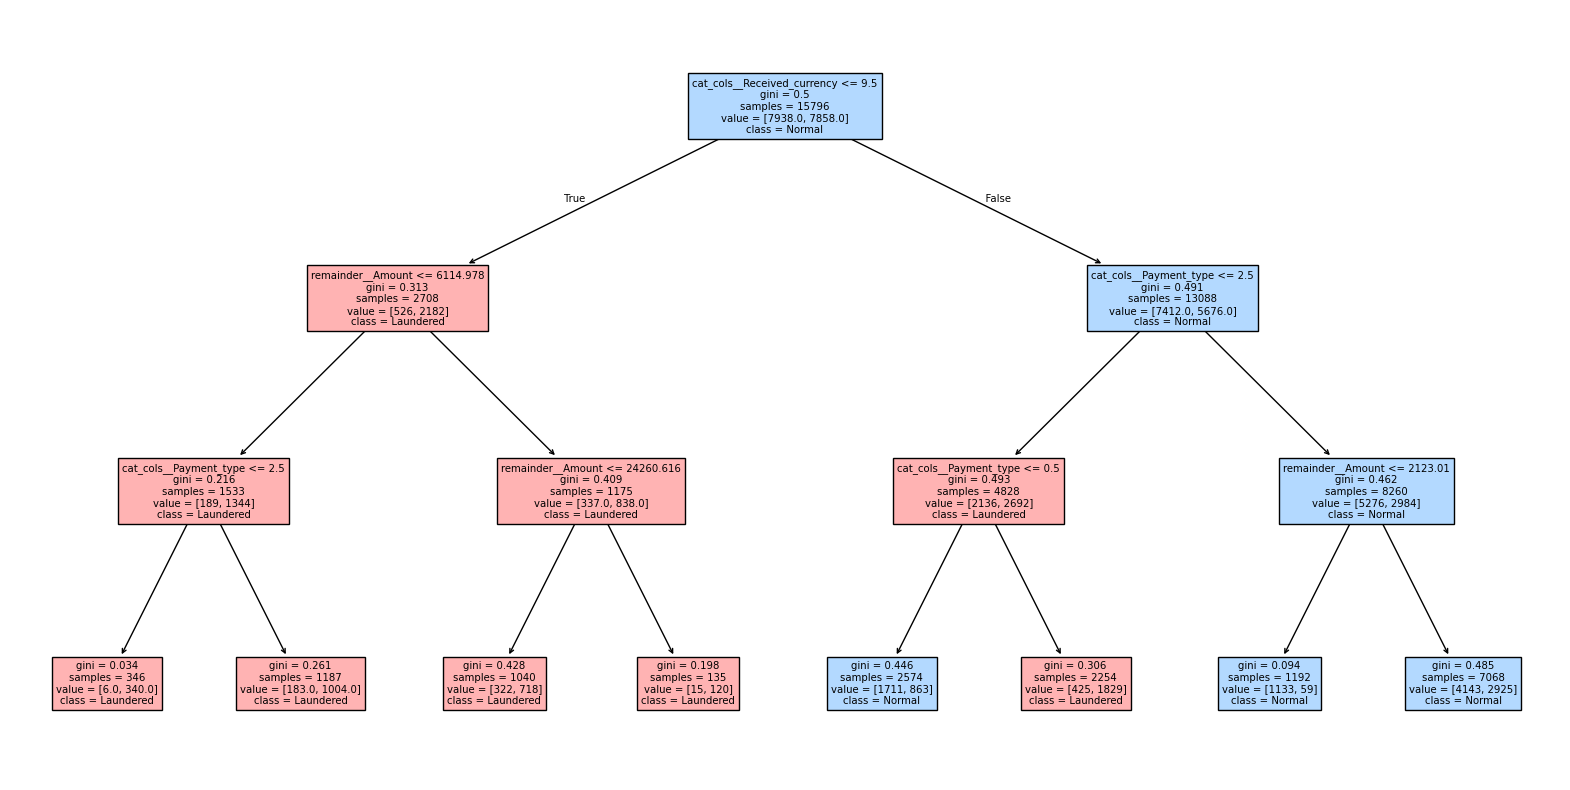

In [28]:
plt.figure(figsize=(20,10))
tree_artists = plot_tree(pipeline_tree['model'], 
                         feature_names=feature_names, 
                         filled=True, 
                         class_names=['Normal', 'Laundered'])

for i in tree_artists:
    a = i.get_text()
    bbox = i.get_bbox_patch()
    
    if bbox is not None:
        if "Normal" in a:
            bbox.set_facecolor("#b3d9ff")
        else:
            bbox.set_facecolor("#ffb3b3")

plt.show()

#### Summarizing the above diagram if for a transaction, the below conditions are met
* Received_currency code is 9.5 or less
* Amount is $6,114.98 or less
* Payment_type code is 2.5 or less

#### then the transaction would be classified as criminal transaction.

### Unmasking the numerical codes

In [32]:
cat_cols

['Payment_currency',
 'Received_currency',
 'Sender_bank_location',
 'Receiver_bank_location',
 'Payment_type']

In [33]:
cat_cols[1]

'Received_currency'

In [76]:
pipeline_tree['preprocessor'].transformers_[0][1].categories_

[array(['Albanian lek', 'Dirham', 'Euro', 'Indian rupee', 'Mexican Peso',
        'Moroccan dirham', 'Naira', 'Pakistani rupee', 'Swiss franc',
        'Turkish lira', 'UK pounds', 'US dollar', 'Yen'], dtype=object),
 array(['Albanian lek', 'Dirham', 'Euro', 'Indian rupee', 'Mexican Peso',
        'Moroccan dirham', 'Naira', 'Pakistani rupee', 'Swiss franc',
        'Turkish lira', 'UK pounds', 'US dollar', 'Yen'], dtype=object),
 array(['Albania', 'Austria', 'France', 'Germany', 'India', 'Italy',
        'Japan', 'Mexico', 'Morocco', 'Netherlands', 'Nigeria', 'Pakistan',
        'Spain', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA'], dtype=object),
 array(['Albania', 'Austria', 'France', 'Germany', 'India', 'Italy',
        'Japan', 'Mexico', 'Morocco', 'Netherlands', 'Nigeria', 'Pakistan',
        'Spain', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA'], dtype=object),
 array(['ACH', 'Cash Deposit', 'Cash Withdrawal', 'Cheque', 'Credit card',
        'Cross-border', 'Debit card'], dtype=

#### 1. Unmasking cat_cols__Received_currency <= 9.5
* The second array in the image output (Received_currency). Listing them out as per the respective index:
* 0: Albanian lek
* 1: Dirham
* 2: Euro
* 3: Indian rupee
* 4: Mexican Peso
* 5: Moroccan dirham
* 6: Naira
* 7: Pakistani rupee
* 8: Swiss franc
* 9: Turkish lira

In [34]:
cat_cols[4]

'Payment_type'

#### Unmasking cat_cols__Payment_type <= 2.5
* Payment_type: Let's list them by index:
* 0: ACH
* 1: Cash Deposit
* 2: Cash Withdrawal
* 3: Cheque

#### The Business Translation: 

##### A transaction is automatically classified as high-risk laundering if it simultaneously meets the following three conditions:

• High-Risk Currency Route: The Received_currency belongs to specific emergent networks (indices 0 through 9: Albanian lek, Dirham, Euro, Indian rupee, Mexican Peso, Moroccan dirham, Naira, Pakistani rupee, Swiss franc, or Turkish lira). Meanwhile, stable standard currencies like UK pounds, US dollars, or Yen route to the safer low-risk branches.

• Transaction Velocity Filtering: The total transfer Amount is $6,114.98 or less. This indicates classic "structuring" or "smurfing" intentionally breaking down massive sums of illicit cash into smaller chunks to evade mandatory bank reporting thresholds.

• Liquid Payment Channels: The Payment_type relies on quick-clearing, high-liquidity financial channels (indices 0, 1, and 2: ACH transfers, Cash Deposits, and Cash Withdrawals). Traditional commercial methods with clear paper trails—like Cheques, Credit cards, or Debit cards—map directly back to regular, safe civilian activity.

## Deployment

### Saving the Pipeline in an object

In [35]:
import joblib

In [36]:
joblib.dump(pipeline_tree, 'aml_profiling_tree.pkl')

['aml_profiling_tree.pkl']

In [37]:
loaded_tree_pipeline = joblib.load('aml_profiling_tree.pkl')

### Testing the Deployment

In [38]:
test_tx = pd.DataFrame([{
    'Payment_currency': 'USD',          
    'Received_currency': 'Euro',        
    'Sender_bank_location': 'USA',
    'Receiver_bank_location': 'UK',
    'Payment_type': 'Cash_Withdrawal',  
    'Amount': 4500.00                  
}])

In [39]:
prediction = loaded_tree_pipeline.predict(test_tx)

In [40]:
print(f"Model Decision: {'Laundered' if prediction[0] == 1 else 'Normal'}")

Model Decision: Laundered
